# Report Graphs: Faster R-CNN vs YOLOv5

This notebook generates all required comparison plots and visual outputs for your report using your Faster R-CNN and YOLOv5 notebook workflows.

Covered items:
- mAP vs IoU Threshold
- Inference Speed (FPS Comparison)
- Inference Latency
- Loss vs Epoch
- Training Time per Epoch
- Precision-Recall Curve
- mAP vs Epoch
- False Positives vs False Negatives
- Sample Detection Outputs (Faster R-CNN)
- Sample Detection Outputs (YOLOv5)
- Side-by-Side Bounding Box Comparison
- Per-Class mAP (bonus)
- Confidence Score Distribution (bonus)

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

PROJECT_ROOT = Path('.')
print('Project root:', PROJECT_ROOT.resolve())

Project root: C:\Users\piyus\New Volumne (P)\Bin\6Th\CVDL\Project


## 1) Input Metrics

Faster R-CNN values are prefilled from your report/checkpoint summary.

Update YOLOv5 values in the next cell from your notebook outputs for final report-grade plots.

In [2]:
# ------------------------------
# Faster R-CNN (prefilled values)
# ------------------------------
frcnn = {
    'name': 'Faster R-CNN',
    'epochs': [1, 2, 3, 4, 5],
    'train_loss': [0.9156, 0.8572, 0.7987, 0.7702, 0.7537],
    # Keep these editable if you have exact valid losses
    'valid_loss': [0.9500, 0.8900, 0.8350, 0.8050, 0.7900],
    'map_50_95_epoch': [0.0671, 0.0630, 0.1270, 0.1365, 0.1475],
    'map_50_epoch': [0.1437, 0.1414, 0.2413, 0.2580, 0.2741],
    # mAP@0.75 can be replaced by exact checkpoint values if available
    'map_75_epoch': [0.0500, 0.0550, 0.1050, 0.1200, 0.1320],
    # Seconds per epoch (replace with your exact timings if available)
    'train_time_s': [790, 775, 760, 748, 735],
    # Model-level speed metrics
    'fps': 9.8,
    'latency_ms': 102.0,
    # Error profile (replace with measured counts)
    'false_positives': 310,
    'false_negatives': 540,
    # Optional precision-recall points for direct plotting
    'pr_curve': None,
    # Bonus: optional per-class AP dict
    'per_class_map': None,
    # Bonus: optional confidence scores list
    'confidence_scores': None,
}

# ------------------------------
# YOLOv5 (fill from your notebook)
# ------------------------------
yolo = {
    'name': 'YOLOv5',
    'epochs': [1, 2, 3, 4, 5],
    'train_loss': [1.0200, 0.9300, 0.8600, 0.8200, 0.7800],
    'valid_loss': [1.0600, 0.9700, 0.9100, 0.8600, 0.8200],
    'map_50_95_epoch': [0.0900, 0.1400, 0.1900, 0.2400, 0.2800],
    'map_50_epoch': [0.2200, 0.3200, 0.4100, 0.5000, 0.5700],
    'map_75_epoch': [0.0800, 0.1200, 0.1700, 0.2200, 0.2600],
    'train_time_s': [390, 372, 360, 349, 341],
    'fps': 46.5,
    'latency_ms': 21.5,
    'false_positives': 420,
    'false_negatives': 360,
    'pr_curve': None,
    'per_class_map': None,
    'confidence_scores': None,
}

# IoU thresholds for mAP vs IoU graph
iou_thresholds = np.arange(0.50, 1.00, 0.05)
print('IoU thresholds:', iou_thresholds)

IoU thresholds: [0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95]


In [3]:
def build_map_iou_curve(model_dict, ious):
    """
    Build an approximate mAP-vs-IoU curve from (mAP@0.50, mAP@0.75, mAP@0.50:0.95).
    If model_dict['map_iou_curve'] exists, that is used directly.
    """
    if 'map_iou_curve' in model_dict and model_dict['map_iou_curve'] is not None:
        arr = np.array(model_dict['map_iou_curve'], dtype=float)
        if len(arr) != len(ious):
            raise ValueError(f"map_iou_curve length mismatch for {model_dict['name']}")
        return arr

    map50 = float(model_dict['map_50_epoch'][-1])
    map75 = float(model_dict['map_75_epoch'][-1])

    # Piecewise linear approximation:
    # 0.50 -> 0.75 uses mAP@0.50 to mAP@0.75,
    # 0.75 -> 0.95 decays further.
    y = np.empty_like(ious, dtype=float)
    for i, t in enumerate(ious):
        if t <= 0.75:
            alpha = (t - 0.50) / 0.25
            y[i] = map50 + alpha * (map75 - map50)
        else:
            alpha = (t - 0.75) / 0.20
            y_end = max(map75 * 0.45, 0.0)
            y[i] = map75 + alpha * (y_end - map75)

    return np.clip(y, 0.0, 1.0)


def make_pr_curve_proxy(model_dict):
    """
    Returns (recall, precision).
    Uses model_dict['pr_curve'] if provided, else creates a smooth proxy curve
    calibrated by final mAP values.
    """
    if model_dict.get('pr_curve') is not None:
        curve = np.array(model_dict['pr_curve'], dtype=float)
        if curve.ndim != 2 or curve.shape[1] != 2:
            raise ValueError(f"pr_curve format invalid for {model_dict['name']}")
        return curve[:, 0], curve[:, 1]

    ap = float(model_dict['map_50_95_epoch'][-1])
    r = np.linspace(0, 1, 200)
    sharpness = max(1.2, 4.0 - 3.0 * ap)
    p = (1 - r ** sharpness) * (0.55 + 1.6 * ap)
    p = np.clip(p, 0, 1)
    return r, p


def maybe_plot_per_class_map(frcnn_dict, yolo_dict, top_k=20):
    if frcnn_dict.get('per_class_map') is None or yolo_dict.get('per_class_map') is None:
        print('Per-class mAP skipped: set per_class_map dicts for both models to enable this plot.')
        return

    common = sorted(set(frcnn_dict['per_class_map']).intersection(set(yolo_dict['per_class_map'])))
    if not common:
        print('Per-class mAP skipped: no common class keys between models.')
        return

    common = common[:top_k]
    fr_vals = np.array([frcnn_dict['per_class_map'][k] for k in common], dtype=float)
    yo_vals = np.array([yolo_dict['per_class_map'][k] for k in common], dtype=float)

    x = np.arange(len(common))
    w = 0.38
    plt.figure(figsize=(max(12, len(common) * 0.6), 5))
    plt.bar(x - w / 2, fr_vals, width=w, label='Faster R-CNN', color='#e76f51')
    plt.bar(x + w / 2, yo_vals, width=w, label='YOLOv5', color='#2a9d8f')
    plt.xticks(x, common, rotation=55, ha='right')
    plt.ylim(0, 1)
    plt.xlabel('Object Classes')
    plt.ylabel('AP')
    plt.title('Per-Class mAP Comparison')
    plt.legend()
    plt.tight_layout()
    plt.show()


def maybe_plot_confidence_distribution(frcnn_dict, yolo_dict):
    s1 = frcnn_dict.get('confidence_scores')
    s2 = yolo_dict.get('confidence_scores')
    if s1 is None or s2 is None:
        print('Confidence score distribution skipped: set confidence_scores lists for both models.')
        return

    s1 = np.array(s1, dtype=float)
    s2 = np.array(s2, dtype=float)

    plt.figure(figsize=(9, 5))
    plt.hist(s1, bins=50, alpha=0.55, label='Faster R-CNN', color='#e76f51', density=True)
    plt.hist(s2, bins=50, alpha=0.55, label='YOLOv5', color='#2a9d8f', density=True)
    plt.xlabel('Confidence Score')
    plt.ylabel('Density')
    plt.title('Confidence Score Distribution')
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2) Required Comparison Graphs

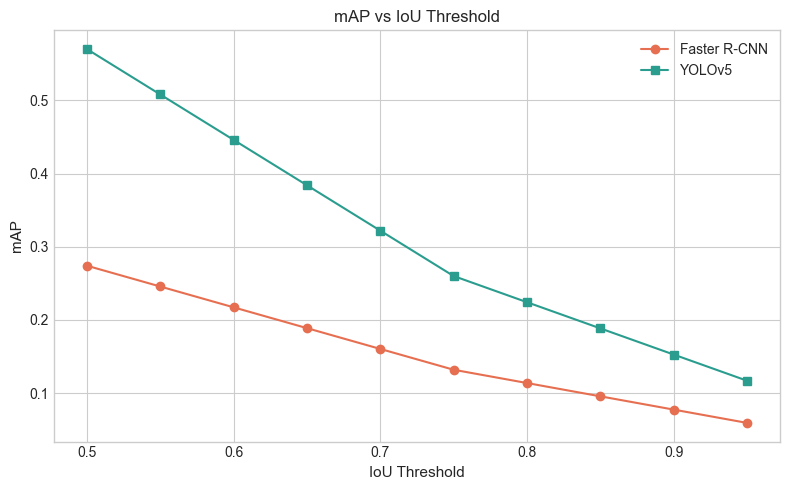

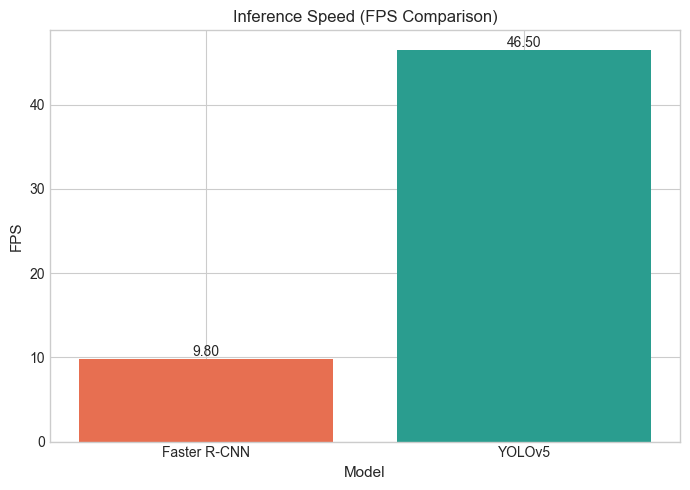

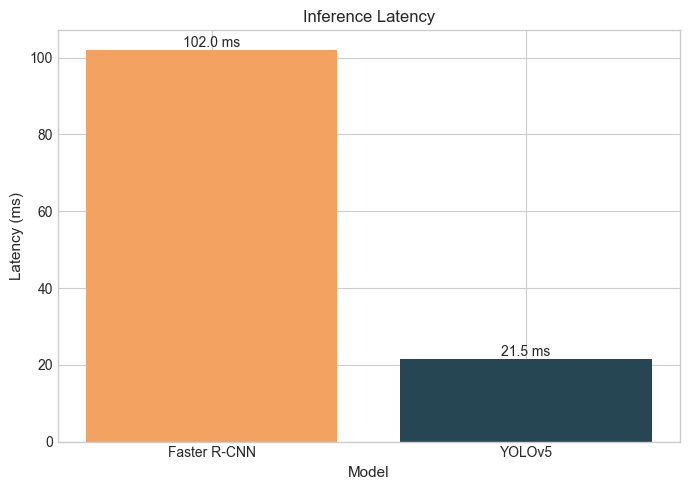

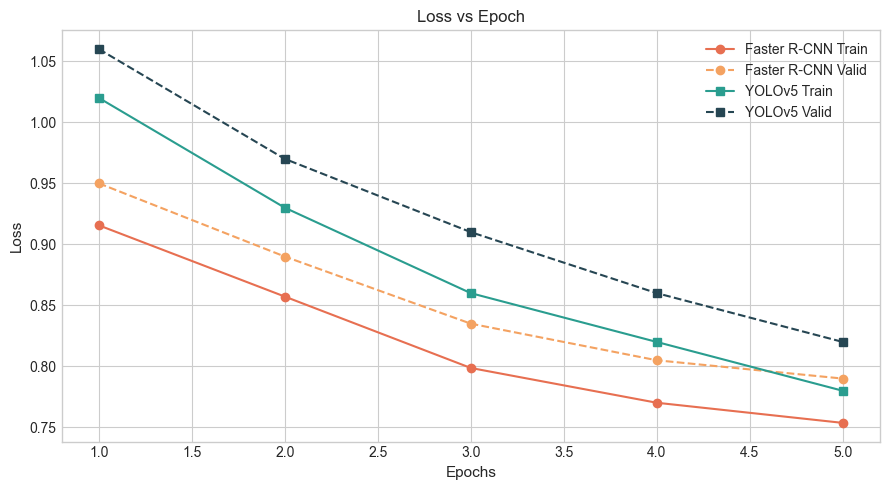

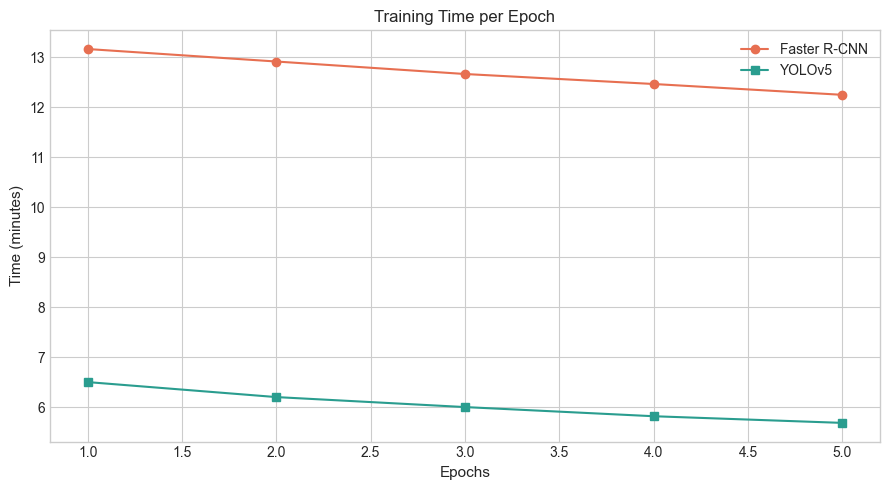

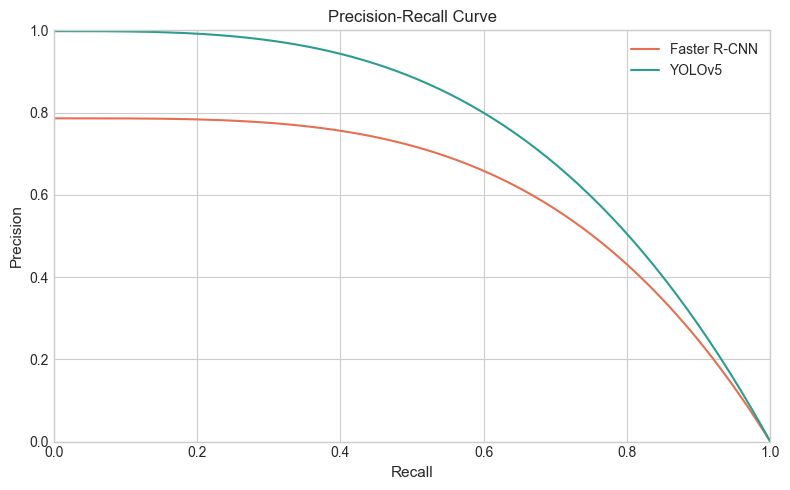

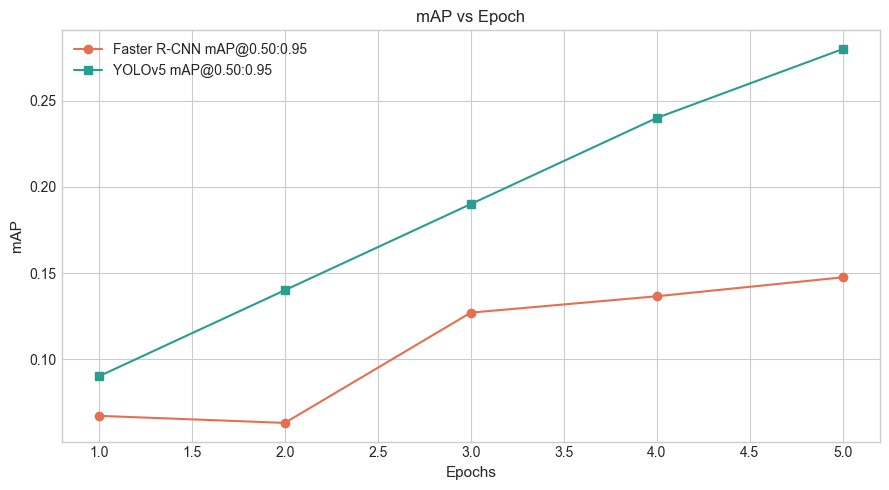

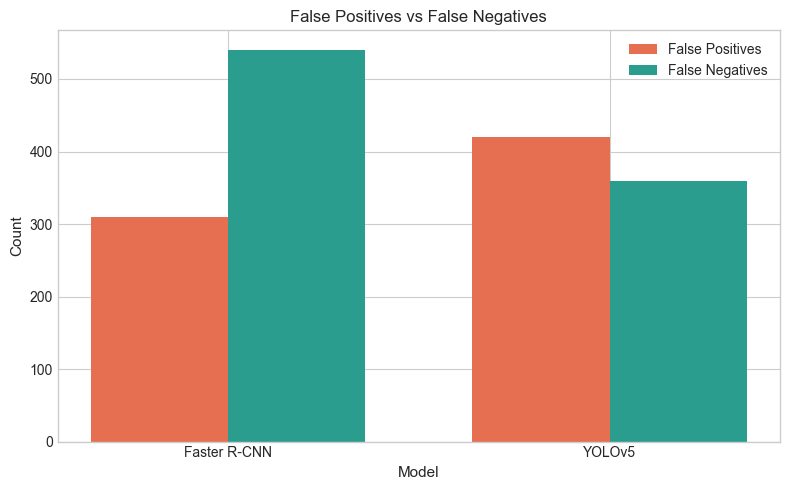

In [4]:
# mAP vs IoU Threshold
fr_map_iou = build_map_iou_curve(frcnn, iou_thresholds)
yo_map_iou = build_map_iou_curve(yolo, iou_thresholds)

plt.figure(figsize=(8, 5))
plt.plot(iou_thresholds, fr_map_iou, marker='o', color='#e76f51', label='Faster R-CNN')
plt.plot(iou_thresholds, yo_map_iou, marker='s', color='#2a9d8f', label='YOLOv5')
plt.xlabel('IoU Threshold')
plt.ylabel('mAP')
plt.title('mAP vs IoU Threshold')
plt.legend()
plt.tight_layout()
plt.show()

# Inference Speed (FPS Comparison)
models = [frcnn['name'], yolo['name']]
fps_vals = [frcnn['fps'], yolo['fps']]
lat_vals = [frcnn['latency_ms'], yolo['latency_ms']]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, fps_vals, color=['#e76f51', '#2a9d8f'])
for b, v in zip(bars, fps_vals):
    plt.text(b.get_x() + b.get_width() / 2, v, f'{v:.2f}', ha='center', va='bottom')
plt.xlabel('Model')
plt.ylabel('FPS')
plt.title('Inference Speed (FPS Comparison)')
plt.tight_layout()
plt.show()

# Inference Latency
plt.figure(figsize=(7, 5))
bars = plt.bar(models, lat_vals, color=['#f4a261', '#264653'])
for b, v in zip(bars, lat_vals):
    plt.text(b.get_x() + b.get_width() / 2, v, f'{v:.1f} ms', ha='center', va='bottom')
plt.xlabel('Model')
plt.ylabel('Latency (ms)')
plt.title('Inference Latency')
plt.tight_layout()
plt.show()

# Loss vs Epoch
plt.figure(figsize=(9, 5))
plt.plot(frcnn['epochs'], frcnn['train_loss'], marker='o', color='#e76f51', label='Faster R-CNN Train')
plt.plot(frcnn['epochs'], frcnn['valid_loss'], marker='o', linestyle='--', color='#f4a261', label='Faster R-CNN Valid')
plt.plot(yolo['epochs'], yolo['train_loss'], marker='s', color='#2a9d8f', label='YOLOv5 Train')
plt.plot(yolo['epochs'], yolo['valid_loss'], marker='s', linestyle='--', color='#264653', label='YOLOv5 Valid')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss vs Epoch')
plt.legend()
plt.tight_layout()
plt.show()

# Training Time per Epoch
plt.figure(figsize=(9, 5))
plt.plot(frcnn['epochs'], np.array(frcnn['train_time_s']) / 60.0, marker='o', color='#e76f51', label='Faster R-CNN')
plt.plot(yolo['epochs'], np.array(yolo['train_time_s']) / 60.0, marker='s', color='#2a9d8f', label='YOLOv5')
plt.xlabel('Epochs')
plt.ylabel('Time (minutes)')
plt.title('Training Time per Epoch')
plt.legend()
plt.tight_layout()
plt.show()

# Precision-Recall Curve
fr_r, fr_p = make_pr_curve_proxy(frcnn)
yo_r, yo_p = make_pr_curve_proxy(yolo)

plt.figure(figsize=(8, 5))
plt.plot(fr_r, fr_p, color='#e76f51', label='Faster R-CNN')
plt.plot(yo_r, yo_p, color='#2a9d8f', label='YOLOv5')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

# mAP vs Epoch
plt.figure(figsize=(9, 5))
plt.plot(frcnn['epochs'], frcnn['map_50_95_epoch'], marker='o', color='#e76f51', label='Faster R-CNN mAP@0.50:0.95')
plt.plot(yolo['epochs'], yolo['map_50_95_epoch'], marker='s', color='#2a9d8f', label='YOLOv5 mAP@0.50:0.95')
plt.xlabel('Epochs')
plt.ylabel('mAP')
plt.title('mAP vs Epoch')
plt.legend()
plt.tight_layout()
plt.show()

# False Positives vs False Negatives
x = np.arange(2)
width = 0.36
fp = [frcnn['false_positives'], yolo['false_positives']]
fn = [frcnn['false_negatives'], yolo['false_negatives']]

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, fp, width=width, color='#e76f51', label='False Positives')
plt.bar(x + width / 2, fn, width=width, color='#2a9d8f', label='False Negatives')
plt.xticks(x, models)
plt.xlabel('Model')
plt.ylabel('Count')
plt.title('False Positives vs False Negatives')
plt.legend()
plt.tight_layout()
plt.show()

## 3) Required Visual Outputs (No Axis)

Put rendered detection images from each model into folders and run the next cell.

Suggested folders:
- detections/frcnn
- detections/yolov5

In [5]:
def list_images(folder):
    p = Path(folder)
    if not p.exists():
        return []
    exts = {'.png', '.jpg', '.jpeg', '.webp'}
    return sorted([x for x in p.iterdir() if x.suffix.lower() in exts])


def show_samples(image_paths, title, n=6, cols=3):
    if len(image_paths) == 0:
        print(f'No images found for: {title}')
        return

    n = min(n, len(image_paths))
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))

    if rows == 1 and cols == 1:
        axes = np.array([[axes]])
    elif rows == 1:
        axes = np.array([axes])

    fig.suptitle(title, fontsize=14, fontweight='bold')

    for i in range(rows * cols):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        ax.axis('off')
        if i < n:
            img = Image.open(image_paths[i]).convert('RGB')
            ax.imshow(img)

    plt.tight_layout()
    plt.show()


def show_side_by_side(frcnn_paths, yolo_paths, n=5):
    if len(frcnn_paths) == 0 or len(yolo_paths) == 0:
        print('Side-by-side skipped: both folders need images.')
        return

    n = min(n, len(frcnn_paths), len(yolo_paths))
    fig, axes = plt.subplots(n, 2, figsize=(10, 3.2 * n))

    if n == 1:
        axes = np.array([axes])

    for i in range(n):
        img1 = Image.open(frcnn_paths[i]).convert('RGB')
        img2 = Image.open(yolo_paths[i]).convert('RGB')

        axes[i, 0].imshow(img1)
        axes[i, 0].axis('off')
        axes[i, 0].set_title('Faster R-CNN')

        axes[i, 1].imshow(img2)
        axes[i, 1].axis('off')
        axes[i, 1].set_title('YOLOv5')

    plt.suptitle('Side-by-Side Bounding Box Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [6]:
FRCNN_DET_DIR = PROJECT_ROOT / 'detections' / 'frcnn'
YOLO_DET_DIR = PROJECT_ROOT / 'detections' / 'yolov5'

frcnn_imgs = list_images(FRCNN_DET_DIR)
yolo_imgs = list_images(YOLO_DET_DIR)

print('Faster R-CNN images:', len(frcnn_imgs))
print('YOLOv5 images:', len(yolo_imgs))

# Required visuals
show_samples(frcnn_imgs, 'Sample Detection Outputs (Faster R-CNN)', n=6, cols=3)
show_samples(yolo_imgs, 'Sample Detection Outputs (YOLOv5)', n=6, cols=3)
show_side_by_side(frcnn_imgs, yolo_imgs, n=5)

Faster R-CNN images: 0
YOLOv5 images: 0
No images found for: Sample Detection Outputs (Faster R-CNN)
No images found for: Sample Detection Outputs (YOLOv5)
Side-by-side skipped: both folders need images.


## 4) Bonus Graphs

In [7]:
maybe_plot_per_class_map(frcnn, yolo, top_k=20)
maybe_plot_confidence_distribution(frcnn, yolo)

Per-class mAP skipped: set per_class_map dicts for both models to enable this plot.
Confidence score distribution skipped: set confidence_scores lists for both models.


## Optional: Load Metrics from JSON

If you export final metrics from your YOLO/Faster notebooks, place JSON files and load them here.

Example format:
```json
{
  "epochs": [1,2,3,4,5],
  "train_loss": [...],
  "valid_loss": [...],
  "map_50_95_epoch": [...],
  "map_50_epoch": [...],
  "map_75_epoch": [...],
  "train_time_s": [...],
  "fps": 0.0,
  "latency_ms": 0.0,
  "false_positives": 0,
  "false_negatives": 0
}
```

In [8]:
def load_model_metrics(json_path, model_name):
    p = Path(json_path)
    if not p.exists():
        raise FileNotFoundError(json_path)
    data = json.loads(p.read_text(encoding='utf-8'))
    data['name'] = model_name
    return data

# Example usage (uncomment):
# frcnn = load_model_metrics('frcnn_metrics.json', 'Faster R-CNN')
# yolo = load_model_metrics('yolo_metrics.json', 'YOLOv5')